# 07 · The decision: should KKBox offer a free month, and to whom?

Part 1 gives every March member a churn probability (notebook 02) and a value (notebook 04).
Part 2 measured what a real retention contact did: the telecom call's doubly robust effect on
two-month churn (notebook 05), turned into a **relative reduction** with its 95% interval, which
runs from a large reduction to an increase. KKBox ran no experiment, so carrying
that relative effect to a free-month offer at a music service is an assumption; the plan
therefore reports the decision across the whole interval and as a **break-even** effect.

Per member: expected value of the offer = P(churn) × relative reduction × lifetime value − cost,
where the cost is one free month (the member's monthly payment) for everyone who stays.

| | |
|---|---|
| **Question** | Should KKBox give at-risk members a free month, and to whom? |
| **Answer** | Not yet. At the telecom campaign's best estimate (14% fewer churners), the offer pays for about 11,000 of 971,000 members, worth about NT$0.57M net a month, but the interval includes no effect at all. Even the best 1% of members need a 12% churn reduction to break even. Recommendation: run a small test (256 members per arm among the highest-risk members) before rolling out. |
| **Next** | The [decision memo](../reports/decision_memo.md) sums up the project. |

In [1]:
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "kkbox.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src import records
from src.data import kkbox, telecom

_, SOURCE = kkbox.connect()
_, TSOURCE = telecom.load()
fdir = kkbox.features_dir(SOURCE)
m = pd.read_parquet(fdir / "mar_scores.parquet").merge(pd.read_parquet(fdir / "mar_ltv.parquet"), on="msno")
eff = records.read("05_campaign_effect", TSOURCE)
base = eff["effect_unadjusted"]["rate_held_back"]
R = {"point": -eff["effect_aipw"]["diff"] / base, "low": -eff["effect_aipw"]["ci"][1] / base,
     "high": -eff["effect_aipw"]["ci"][0] / base}
print(f"sources: KKBox {SOURCE}, telecom {TSOURCE}; {len(m):,} March members")
print("relative churn reduction from the telecom experiment:", {k: f"{v:+.0%}" for k, v in R.items()})

sources: KKBox real, telecom real; 970,960 March members
relative churn reduction from the telecom experiment: {'point': '+14%', 'low': '-14%', 'high': '+41%'}


## 1. Expected value of the offer, member by member

In [2]:
p, v, c = m["p_churn"].to_numpy(), m["ltv"].to_numpy(), m["monthly_paid"].to_numpy()


def ev(r, ltv=v):
    return p * r * ltv - c * (1 - p + p * r)


rows = []
for name, r in R.items():
    e = ev(r)
    pos = e > 0
    rows.append({"effect": name, "relative_reduction": r, "members_worth_offering": int(pos.sum()),
                 "share": float(pos.mean()), "net_value_ntd": float(e[pos].sum()),
                 "cost_ntd": float((c * (1 - p + p * r))[pos].sum()),
                 "churners_kept": float((p * r)[pos].sum())})
table = pd.DataFrame(rows).set_index("effect")
breakeven = np.where(p * (v - c) > 0, c * (1 - p) / np.maximum(p * (v - c), 1e-9), np.inf)
be_q = {f"top_{q}": float(np.quantile(breakeven, q / 100)) for q in (1, 5, 10)}
table.round(3)

,relative_reduction,members_worth_offering,share,net_value_ntd,cost_ntd,churners_kept
effect,,,,,,
point,0.135,10722,0.011,574226.850,334078.844,1286.687
low,-0.139,0,0.000,0.000,0.000,0.000
high,0.410,33333,0.034,3188167.539,2820240.556,8417.329


**Break-even.** For each member, the relative churn reduction the offer must achieve to pay
for itself. Even for the most promising members (the lowest 1% / 5% / 10% of break-even
values) the bar is:

In [3]:
print({k: f"{x:.0%}" for k, x in be_q.items()}, "| telecom estimate", f"{R['point']:.0%}")
sens = {}
for col in [c_ for c_ in m.columns if c_.startswith("ltv_")]:
    e = ev(R["point"], m[col].to_numpy())
    sens[col] = {"members_worth_offering": int((e > 0).sum()), "net_value_ntd": float(e[e > 0].sum())}
pd.DataFrame(sens).T

{'top_1': '12%', 'top_5': '143%', 'top_10': '265%'} | telecom estimate 14%


,members_worth_offering,net_value_ntd
ltv_24_30,10722.0,574226.850090
ltv_12_30,8109.0,220876.104699
ltv_36_30,17086.0,973786.939037
ltv_24_20,8379.0,302403.560229
ltv_24_40,16107.0,926019.502236


## 2. What it would take to know

The telecom interval is too wide to decide on. The members for whom an offer could plausibly pay
are those whose break-even effect lies inside that interval. A KKBox test of the offer on them
must be able to detect their median break-even effect:

In [4]:
plausible = breakeven <= R["high"]
if plausible.sum() >= 100:
    p_top = float(p[plausible].mean())
    r_needed = float(np.median(breakeven[plausible]))
    z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
    delta = p_top * r_needed
    n_arm = int(np.ceil(2 * z ** 2 * p_top * (1 - p_top) / delta ** 2))
    test = {"members": int(plausible.sum()), "target_churn": p_top, "relative_effect": r_needed, "n_per_arm": n_arm}
    print(f"{int(plausible.sum()):,} members could plausibly be worth an offer; they churn at {p_top:.1%}. Detecting a "
          f"{r_needed:.0%} relative cut ({delta * 100:.2f} points) needs {n_arm:,} per arm.")
else:
    test = {"members": int(plausible.sum())}
    print("Fewer than 100 members could plausibly be worth an offer even at the top of the interval: no test is worth running.")

33,333 members could plausibly be worth an offer; they churn at 61.6%. Detecting a 20% relative cut (12.05 points) needs 256 per arm.


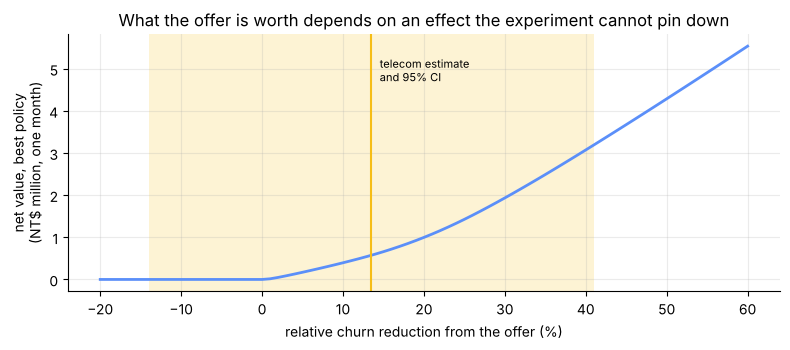

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
grid = np.linspace(-0.2, 0.6, 81)
vals = [ev(r)[ev(r) > 0].sum() / 1e6 for r in grid]
ax.plot(grid * 100, vals, color="#5B8FF9", lw=2)
ax.axvspan(R["low"] * 100, R["high"] * 100, color="#F6BD16", alpha=0.18, lw=0)
ax.axvline(R["point"] * 100, color="#F6BD16", lw=1.5)
ax.annotate("telecom estimate\nand 95% CI", (R["point"] * 100, max(vals) * 0.85), xytext=(6, 0), textcoords="offset points", fontsize=8)
ax.set(xlabel="relative churn reduction from the offer (%)", ylabel="net value, best policy\n(NT$ million, one month)",
       title="What the offer is worth depends on an effect the experiment cannot pin down")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "07_retention_decision.png", SOURCE)

**How to read the figure.** The horizontal axis is how much the offer would cut churn; the curve is the net value of the best policy at that effect. The yellow line and band are the telecom estimate and its 95% interval. Where the curve is above zero the offer pays; the band covers both paying and not paying, which is exactly why the recommendation is a test.

## 3. Summaries for the demo app

The app cannot ship member-level scores (KKBox data may not be redistributed), so it gets
aggregates: the share of churners reached when contacting the top x% by score, and the best
policy's size and value over a grid of effects and margins.

In [6]:
order = np.argsort(-p, kind="stable")
yy = m["is_churn"].to_numpy()[order]
reach = [{"share_contacted": q / 100, "churners_reached": float(yy[: int(round(q / 100 * len(yy)))].sum() / yy.sum())}
         for q in range(0, 101, 5)]
grid_rows = []
for col, margin in (("ltv_24_20", 0.2), ("ltv_24_30", 0.3), ("ltv_24_40", 0.4)):
    for r in np.round(np.arange(-0.2, 0.61, 0.02), 2):
        e = ev(r, m[col].to_numpy())
        grid_rows.append({"margin": margin, "relative_reduction": float(r), "members": int((e > 0).sum()),
                          "net_value_ntd": float(e[e > 0].sum())})

In [7]:
record = {"reach_curve": reach, "value_grid": grid_rows, "relative_reduction": R, "policy": table.reset_index().to_dict(orient="records"), "breakeven": be_q,
          "sensitivity_point": sens, "test_size": test}
print("wrote", records.write("07_retention_decision", record, SOURCE).name)
pt = table.loc["point"]
print(f"At the telecom estimate ({R['point']:.0%} fewer churners), {int(pt['members_worth_offering']):,} of {len(m):,} March "
      f"members are worth an offer, for NT${pt['net_value_ntd'] / 1e6:.2f}M net; even the best 1% of members need a "
      f"{be_q['top_1']:.0%} cut to break even.")

wrote 07_retention_decision.json
At the telecom estimate (14% fewer churners), 10,722 of 970,960 March members are worth an offer, for NT$0.57M net; even the best 1% of members need a 12% cut to break even.


## Takeaways

- **Decide across the uncertainty, not at the point estimate.** At the best guess the offer pays for a small group; at the bottom of the interval it pays for no one.
- **Break-even is a useful way to talk to the business:** "the offer must cut churn by at least 12% for even the best members".
- **The cheapest way to know is a test**, and a small one is enough.

**Back to:** the [README](../README.md) or the [decision memo](../reports/decision_memo.md).